# Model 2 · 1. EDA dataset jenis jerawat (`jenis_v3`)

Model 2 menebak **jenis** dari potongan satu jerawat: Blackheads, Cyst, Papules, Pustules, Whiteheads.
Notebook ini hanya membaca data. *Bukan alat diagnosis medis.*

| Bagian | Isi | Dipakai untuk |
|---|---|---|
| `train` | potongan jerawat + foto close-up | melatih model |
| `val` | potongan jerawat (`C_*`) | memilih model |
| `test_potongan` | potongan jerawat | **ujian akhir** (sekali) |
| `test` | foto close-up | ujian tambahan |

Potongan = satu kotak jerawat yang dipotong dari foto wajah (`C_*.jpg`). Close-up = foto dekat satu jenis jerawat (`V1_*.jpg`).

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data'
print('folder proyek:', ROOT)

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

KELAS = ['Blackheads', 'Cyst', 'Papules', 'Pustules', 'Whiteheads']
BAGIAN = ['train', 'val', 'test_potongan', 'test']

folder proyek: C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL


## 1. Jumlah gambar per bagian dan per jenis

bagian      train  val  test_potongan  test
jenis                                      
Blackheads   1971  185            171    22
Cyst         1130   98             58    22
Papules      1845  230            235     7
Pustules     1851  174            171     9
Whiteheads   1821  185            160    16
TOTAL        8618  872            795    76

Tipe gambar per bagian:
tipe           close-up  potongan
bagian                           
train              2105      6513
val                  70       802
test_potongan         0       795
test                 76         0


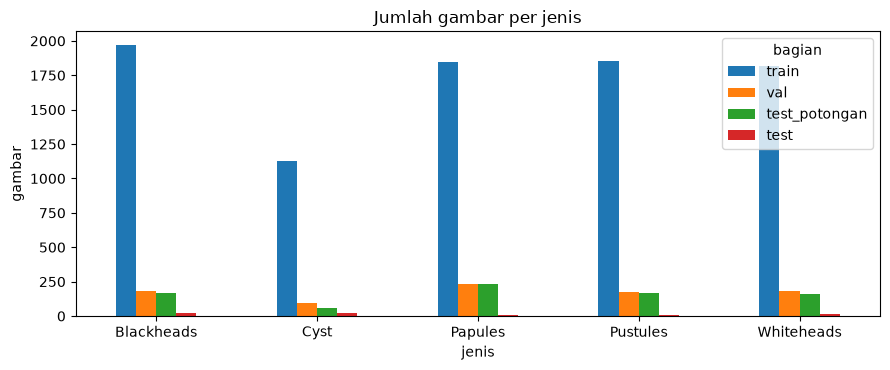

In [2]:
rows = []
for b in BAGIAN:
    for k in KELAS:
        for f in (DATA / 'jenis_v3' / b / k).glob('*'):
            rows.append({'bagian': b, 'jenis': k, 'file': f.name, 'path': f,
                         'tipe': 'potongan' if f.name.startswith('C_') else 'close-up'})
df = pd.DataFrame(rows)
jumlah = df.pivot_table(index='jenis', columns='bagian', values='file', aggfunc='count').reindex(columns=BAGIAN)
jumlah.loc['TOTAL'] = jumlah.sum()
print(jumlah.to_string())
print()
print('Tipe gambar per bagian:')
print(df.pivot_table(index='bagian', columns='tipe', values='file', aggfunc='count').fillna(0).astype(int).reindex(BAGIAN).to_string())

jumlah.drop('TOTAL').plot.bar(figsize=(9, 3.8), title='Jumlah gambar per jenis')
plt.ylabel('gambar'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Catatan:** Cyst paling sedikit (1.130 di train, 58 di ujian). Data tidak seimbang, jadi selain akurasi kita juga
melihat **macro F1** (rata-rata F1 tiap jenis, semua jenis dianggap sama penting).

## 2. Contoh gambar tiap jenis (train)

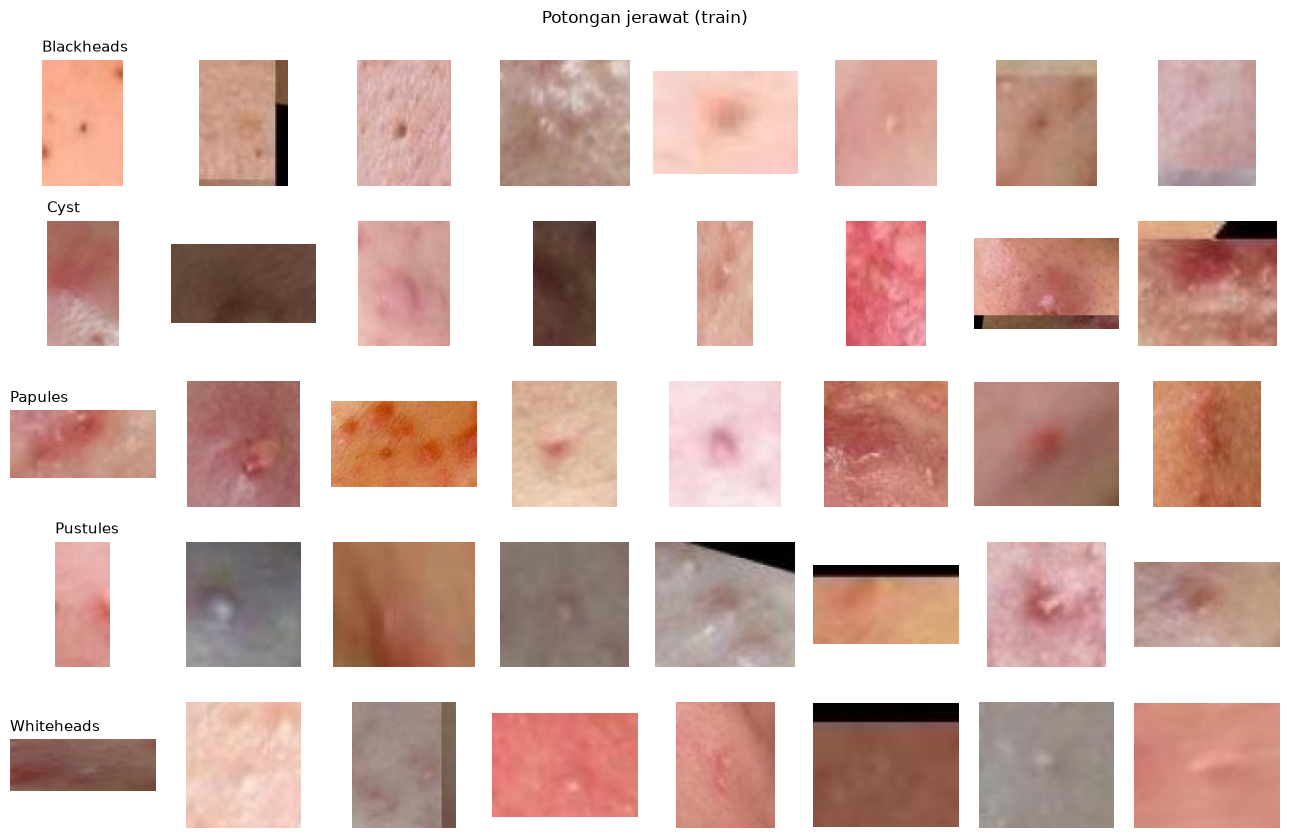

In [3]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(5, 8, figsize=(13, 8.5))
for i, k in enumerate(KELAS):
    calon = df[(df.bagian == 'train') & (df.jenis == k) & (df.tipe == 'potongan')]
    for j, p in enumerate(rng.choice(calon.path.values, 8, replace=False)):
        ax[i, j].imshow(Image.open(p).convert('RGB')); ax[i, j].axis('off')
    ax[i, 0].set_title(k, fontsize=11, loc='left')
plt.suptitle('Potongan jerawat (train)'); plt.tight_layout(); plt.show()

## 3. Ukuran asli potongan
File potongan sudah diperbesar, jadi ukuran asli diambil dari `manifest_potongan_v2.csv` (kolom `sisi_px`,
sisi kotak di foto asli dalam piksel).

potongan dengan data ukuran: 8110 dari 8110
             count   min   25%   50%   75%    max
jenis                                            
Blackheads  1798.0  24.0  31.0  41.0  58.0  381.0
Cyst         684.0  24.0  42.0  60.0  88.0  324.0
Papules     1957.0  24.0  35.0  46.0  61.0  241.0
Pustules    1837.0  24.0  34.0  44.0  56.0  176.0
Whiteheads  1834.0  24.0  32.0  41.0  54.0  245.0


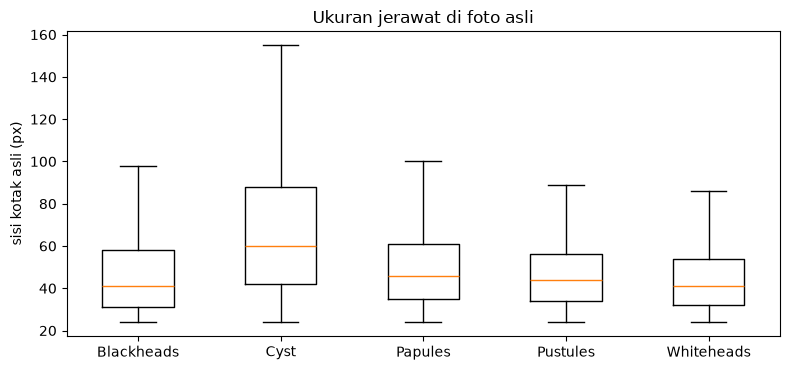

Potongan lebih kecil dari 40 px: 39%


In [4]:
man = pd.read_csv(DATA / 'jenis_v3' / 'manifest_potongan_v2.csv')
ada = df[df.tipe == 'potongan'][['bagian', 'jenis', 'file']]
ukuran = ada.merge(man[['file_baru', 'sisi_px']], left_on='file', right_on='file_baru', how='left')
print('potongan dengan data ukuran:', ukuran.sisi_px.notna().sum(), 'dari', len(ukuran))
print(ukuran.groupby('jenis').sisi_px.describe()[['count', 'min', '25%', '50%', '75%', 'max']].round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot([ukuran[ukuran.jenis == k].sisi_px.dropna() for k in KELAS], showfliers=False)
ax.set_xticks(range(1, 6), KELAS)
ax.set_ylabel('sisi kotak asli (px)'); ax.set_title('Ukuran jerawat di foto asli'); plt.tight_layout(); plt.show()
print('Potongan lebih kecil dari 40 px:', f"{(ukuran.sisi_px < 40).mean():.0%}")

Jerawat di foto asli kecil (median 41-60 px; 39% di bawah 40 px), karena foto dataset paling besar 640 px.
Detail kecil seperti titik putih atau titik hitam sering hanya beberapa piksel. Ini salah satu batas utama akurasi.

## 4. Warna rata-rata tiap jenis
Dihitung dari 300 potongan acak per jenis (ruang warna Lab: L = terang, a = merah, b = kuning).

            L (terang)  a (merah)  b (kuning)
jenis                                        
Blackheads        62.6       13.4        14.1
Cyst              53.7       19.5        15.0
Papules           58.9       16.8        14.2
Pustules          57.7       17.4        13.9
Whiteheads        62.0       13.3        14.8


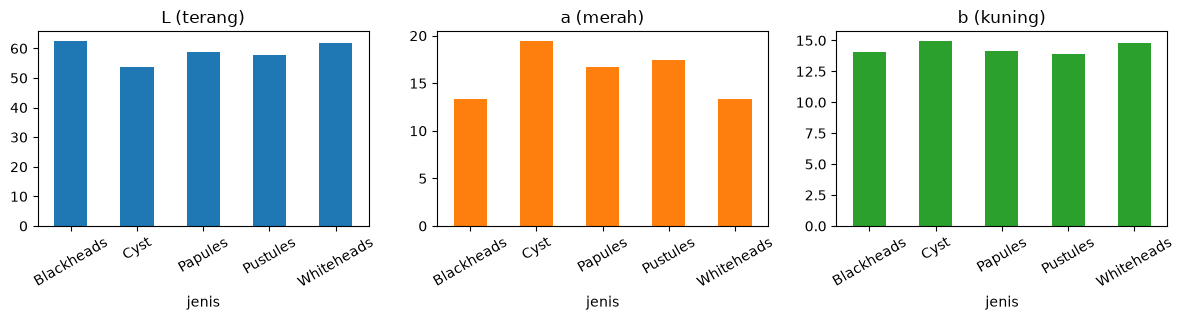

In [5]:
from skimage.color import rgb2lab

warna = []
for k in KELAS:
    calon = df[(df.bagian == 'train') & (df.jenis == k) & (df.tipe == 'potongan')].path.values
    for p in rng.choice(calon, 300, replace=False):
        lab = rgb2lab(np.asarray(Image.open(p).convert('RGB').resize((32, 32)), np.float32) / 255)
        warna.append({'jenis': k, 'L (terang)': lab[..., 0].mean(), 'a (merah)': lab[..., 1].mean(), 'b (kuning)': lab[..., 2].mean()})
warna = pd.DataFrame(warna)
print(warna.groupby('jenis').mean().round(1).to_string())
warna.groupby('jenis').mean().plot.bar(subplots=True, layout=(1, 3), figsize=(12, 3.3), legend=False, rot=30)
plt.tight_layout(); plt.show()

Papules dan Cyst lebih merah, Blackheads lebih gelap. Perbedaannya ada, tapi rata-rata antar jenis saling berdekatan,
jadi warna rata-rata saja tidak cukup. Karena itu di preprocessing ditambah ciri **titik tengah** (notebook 2).

## 5. Pembersihan data: kembaran dibuang dari val dan ujian
Dataset asli (`jenis_v2`) berisi foto yang sama dalam beberapa versi (dibalik/diputar oleh Roboflow). Kalau versi
yang satu ada di train dan yang lain di ujian, nilai ujian jadi terlalu tinggi (**bocor**).
Di `jenis_v3`, soal val/ujian yang punya **kembaran** di train dibuang. Train tidak diubah.
Aturan kembar: kemiripan piksel 32x32 >= 0,97 dan selisih warna <= 5, atau kemiripan >= 0,995
(skrip: `src/persiapan_data/buang_kembar_jenis_v3.py`).

In [6]:
ring = json.load(open(DATA / 'jenis_v3' / 'ringkasan.json'))
tab = pd.DataFrame({b: {'sebelum (v2)': sum(v['v2'] for v in ring['jumlah'][b].values()),
                        'sesudah (v3)': sum(v['v3'] for v in ring['jumlah'][b].values())} for b in BAGIAN}).T
tab['dibuang'] = tab['sebelum (v2)'] - tab['sesudah (v3)']
print(tab.to_string())
dib = pd.read_csv(DATA / 'jenis_v3' / 'dibuang_v3.csv')
print('\nLabel kembaran sama dengan label soal:', f"{dib.label_sama.mean():.0%}")

               sebelum (v2)  sesudah (v3)  dibuang
train                  8618          8618        0
val                    1183           872      311
test_potongan          1102           795      307
test                     80            76        4

Label kembaran sama dengan label soal: 95%


## Kesimpulan EDA
1. Data **tidak seimbang**: Cyst paling sedikit → nilai dilaporkan dengan macro F1 juga.
2. Jerawat di foto asli **kecil** (banyak di bawah 40 px) → detail sulit terlihat.
3. Warna antar jenis **mirip** → perlu ciri tambahan di bagian tengah jerawat.
4. Val dan ujian sudah **dibersihkan dari kembaran** supaya nilai ujian jujur.